# IndoBERT Fully-Connected

In [1]:
pip install transformers datasets torch scikit-learn tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import ast
import re
import torch
import torch.nn as nn
import time
from tqdm import tqdm
from sklearn.model_selection import KFold
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
import os
from sklearn.model_selection import StratifiedKFold
from transformers import get_linear_schedule_with_warmup
import copy
import numpy as np

c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Dataset

In [3]:
df = pd.read_csv("dataset-final.csv")

def extract_label(x):
    if pd.isna(x):
        return None

    if isinstance(x, list):
        return str(x[0]).strip() if len(x) > 0 else None

    x = str(x).strip()

    if x.startswith("[") and x.endswith("]"):
        try:
            labels = ast.literal_eval(x)
            if isinstance(labels, list) and len(labels) > 0:
                return str(labels[0]).strip()
        except Exception:
            pass

    return x

df["label"] = df["label"].apply(extract_label)

df["label"] = (
    df["label"]
    .astype(str)
    .str.strip()
)

CLASS_NAMES = sorted(df["label"].unique())

LABEL_MAP = {
    label: idx
    for idx, label in enumerate(CLASS_NAMES)
}

df["label"] = df["label"].map(LABEL_MAP)

## Preprocessing

In [4]:
df = df.dropna(subset=["text"])

df["text"] = df["text"].astype(str)


def clean_text(text):
    text = text.lower()
    text = re.sub(r'\busername\b', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^a-zA-Z\s!?]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


df["text"] = df["text"].apply(clean_text)

texts = df["text"].tolist()
labels = df["label"].tolist()

print("Jumlah kelas :", len(CLASS_NAMES))
print("Class names  :", CLASS_NAMES)

Jumlah kelas : 2
Class names  : ['bullying', 'non-bullying']


## Tokenizer

In [5]:
tokenizer = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p2")

In [6]:
lengths = [
    len(tokenizer.tokenize(text))
    for text in df["text"]
]

print(max(lengths))
print(np.mean(lengths))
print(np.median(lengths))
print(np.percentile(lengths, 95))

177
27.525
22.0
67.0


## Dataset Class

In [7]:
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=128,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
            'text': self.texts[idx]
        }

## Model

In [8]:
class IndoBERTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("indobenchmark/indobert-base-p2")
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(768, 5)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_output = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls_output)
        logits = self.fc(x)
        return logits

## Konfigurasi

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CONFIG = {
    "epochs": 5,
    "batch_size": 16,
    "lr": 2e-5,          
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "max_grad_norm": 1.0,
    "patience": 2,
    "n_splits": 5,
    "random_state": 42
}

LEARNING_RATES = [
    1e-5,
    2e-5,
    3e-5
]

kf = StratifiedKFold(
    n_splits=CONFIG["n_splits"],
    shuffle=True,
    random_state=CONFIG["random_state"]
)

def setup_model(device, lr):
    model = IndoBERTClassifier().to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=CONFIG["weight_decay"]
    )

    criterion = nn.CrossEntropyLoss()

    return model, optimizer, criterion

## Training 

In [10]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = model(input_ids, attention_mask)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            CONFIG["max_grad_norm"]
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(loader)

## Validation

In [11]:
def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels, all_texts, all_probs = [], [], [], []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids, attention_mask)

            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_texts.extend(batch['text'])

    return all_preds, all_labels, all_texts, all_probs

## Main Loop


EKSPERIMEN LEARNING RATE = 1e-05


===== FOLD 1 =====
Learning Rate: 1e-05 | Fold 1/5
Epoch 1 | Loss: 1.0653 | Acc: 0.9000
Epoch 2 | Loss: 0.2451 | Acc: 0.9500
Epoch 3 | Loss: 0.1352 | Acc: 0.9375
Epoch 4 | Loss: 0.0791 | Acc: 0.9750
Epoch 5 | Loss: 0.0546 | Acc: 0.9625

=== METRICS ===
Accuracy : 0.9750
Precision: 0.9750
Recall   : 0.9750
F1 Score : 0.9750

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.97      0.97      0.97        40
non-bullying       0.97      0.97      0.97        40

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80


Confusion Matrix:
[[39  1]
 [ 1 39]]


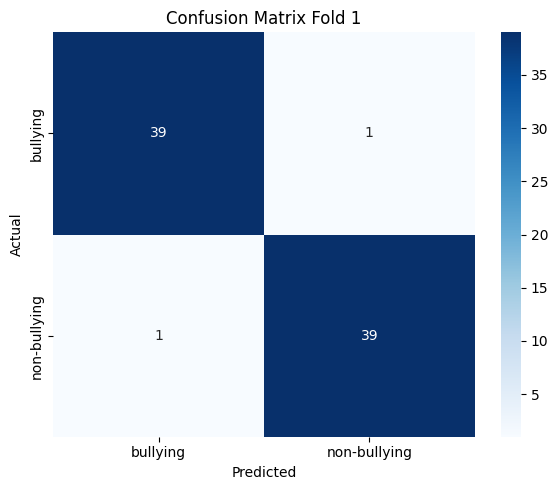


===== FOLD 2 =====
Learning Rate: 1e-05 | Fold 2/5
Epoch 1 | Loss: 1.0272 | Acc: 0.8125
Epoch 2 | Loss: 0.3186 | Acc: 0.8750
Epoch 3 | Loss: 0.1519 | Acc: 0.8750
Epoch 4 | Loss: 0.0966 | Acc: 0.8875
Epoch 5 | Loss: 0.0703 | Acc: 0.8750

=== METRICS ===
Accuracy : 0.8875
Precision: 0.8877
Recall   : 0.8875
F1 Score : 0.8875

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.90      0.88      0.89        40
non-bullying       0.88      0.90      0.89        40

    accuracy                           0.89        80
   macro avg       0.89      0.89      0.89        80
weighted avg       0.89      0.89      0.89        80


Confusion Matrix:
[[35  5]
 [ 4 36]]


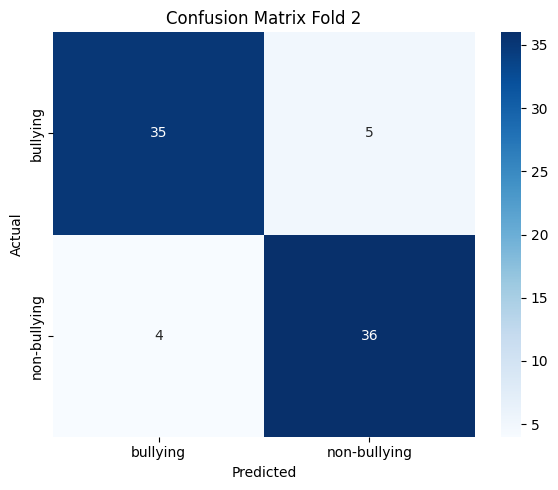


===== FOLD 3 =====
Learning Rate: 1e-05 | Fold 3/5
Epoch 1 | Loss: 1.0131 | Acc: 0.8250
Epoch 2 | Loss: 0.3070 | Acc: 0.8875
Epoch 3 | Loss: 0.1547 | Acc: 0.9000
Epoch 4 | Loss: 0.1212 | Acc: 0.9125
Epoch 5 | Loss: 0.0560 | Acc: 0.9250

=== METRICS ===
Accuracy : 0.9250
Precision: 0.9293
Recall   : 0.9250
F1 Score : 0.9248

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.97      0.88      0.92        40
non-bullying       0.89      0.97      0.93        40

    accuracy                           0.93        80
   macro avg       0.93      0.93      0.92        80
weighted avg       0.93      0.93      0.92        80


Confusion Matrix:
[[35  5]
 [ 1 39]]


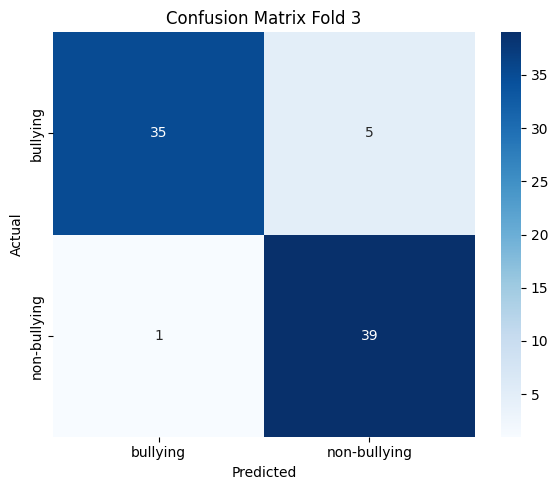


===== FOLD 4 =====
Learning Rate: 1e-05 | Fold 4/5
Epoch 1 | Loss: 0.9515 | Acc: 0.8750
Epoch 2 | Loss: 0.2630 | Acc: 0.9250
Epoch 3 | Loss: 0.1203 | Acc: 0.9250
Epoch 4 | Loss: 0.0642 | Acc: 0.9250
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9250
Precision: 0.9348
Recall   : 0.9250
F1 Score : 0.9246

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.87      1.00      0.93        40
non-bullying       1.00      0.85      0.92        40

    accuracy                           0.93        80
   macro avg       0.93      0.93      0.92        80
weighted avg       0.93      0.93      0.92        80


Confusion Matrix:
[[40  0]
 [ 6 34]]


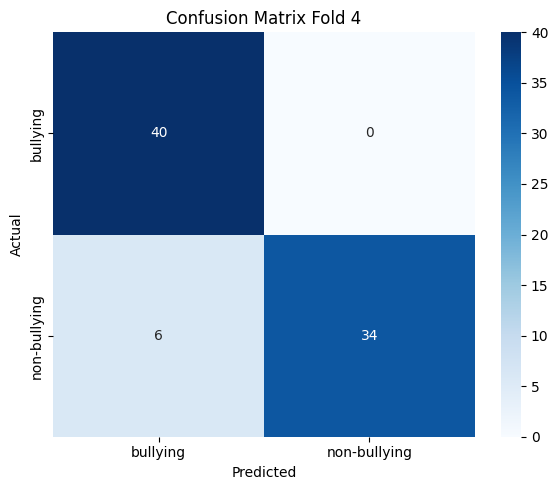


===== FOLD 5 =====
Learning Rate: 1e-05 | Fold 5/5
Epoch 1 | Loss: 0.9243 | Acc: 0.8250
Epoch 2 | Loss: 0.2426 | Acc: 0.8750
Epoch 3 | Loss: 0.1368 | Acc: 0.9375
Epoch 4 | Loss: 0.0789 | Acc: 0.9250
Epoch 5 | Loss: 0.0547 | Acc: 0.9375
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9375
Precision: 0.9400
Recall   : 0.9375
F1 Score : 0.9374

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.91      0.97      0.94        40
non-bullying       0.97      0.90      0.94        40

    accuracy                           0.94        80
   macro avg       0.94      0.94      0.94        80
weighted avg       0.94      0.94      0.94        80


Confusion Matrix:
[[39  1]
 [ 4 36]]


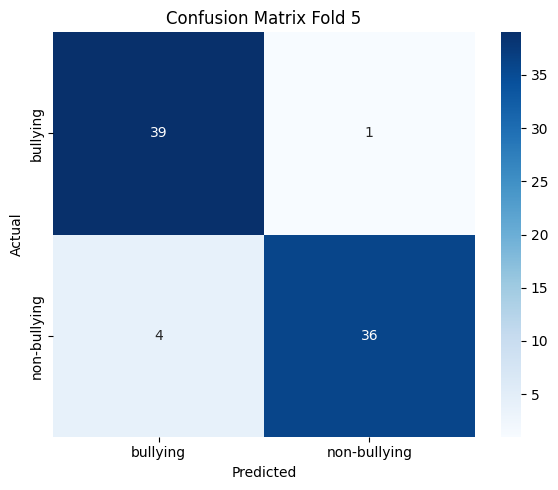


EKSPERIMEN LEARNING RATE = 2e-05


===== FOLD 1 =====
Learning Rate: 2e-05 | Fold 1/5
Epoch 1 | Loss: 0.9162 | Acc: 0.9125
Epoch 2 | Loss: 0.2991 | Acc: 0.9625
Epoch 3 | Loss: 0.0992 | Acc: 0.9750
Epoch 4 | Loss: 0.0271 | Acc: 0.9750
Epoch 5 | Loss: 0.0056 | Acc: 0.9875

=== METRICS ===
Accuracy : 0.9875
Precision: 0.9878
Recall   : 0.9875
F1 Score : 0.9875

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       1.00      0.97      0.99        40
non-bullying       0.98      1.00      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80


Confusion Matrix:
[[39  1]
 [ 0 40]]


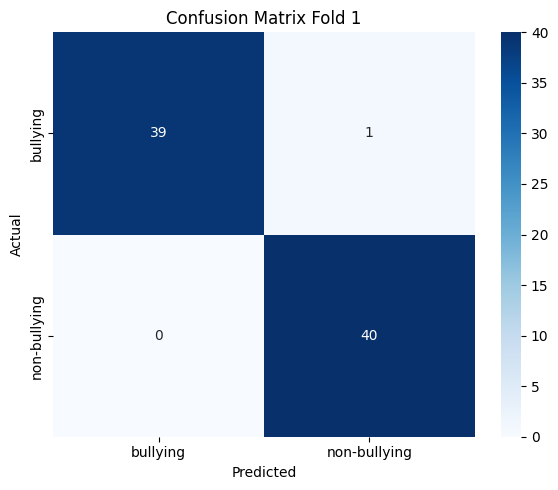


===== FOLD 2 =====
Learning Rate: 2e-05 | Fold 2/5
Epoch 1 | Loss: 0.7314 | Acc: 0.8625
Epoch 2 | Loss: 0.1655 | Acc: 0.8875
Epoch 3 | Loss: 0.0595 | Acc: 0.8875
Epoch 4 | Loss: 0.0141 | Acc: 0.9000
Epoch 5 | Loss: 0.0011 | Acc: 0.8875

=== METRICS ===
Accuracy : 0.9000
Precision: 0.9000
Recall   : 0.9000
F1 Score : 0.9000

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.90      0.90      0.90        40
non-bullying       0.90      0.90      0.90        40

    accuracy                           0.90        80
   macro avg       0.90      0.90      0.90        80
weighted avg       0.90      0.90      0.90        80


Confusion Matrix:
[[36  4]
 [ 4 36]]


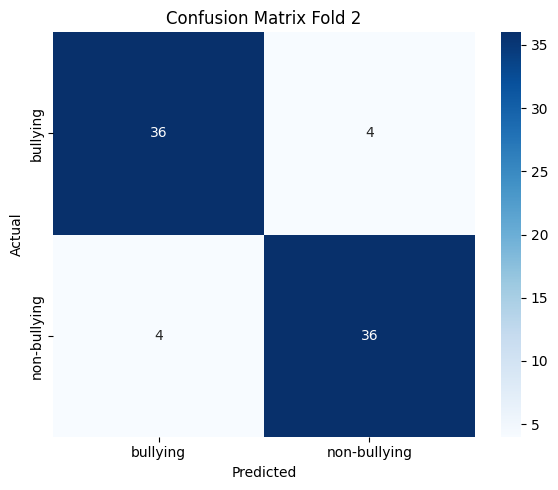


===== FOLD 3 =====
Learning Rate: 2e-05 | Fold 3/5
Epoch 1 | Loss: 0.9309 | Acc: 0.8625
Epoch 2 | Loss: 0.1750 | Acc: 0.9000
Epoch 3 | Loss: 0.0659 | Acc: 0.9125
Epoch 4 | Loss: 0.0272 | Acc: 0.9375
Epoch 5 | Loss: 0.0100 | Acc: 0.9000

=== METRICS ===
Accuracy : 0.9375
Precision: 0.9378
Recall   : 0.9375
F1 Score : 0.9375

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.95      0.93      0.94        40
non-bullying       0.93      0.95      0.94        40

    accuracy                           0.94        80
   macro avg       0.94      0.94      0.94        80
weighted avg       0.94      0.94      0.94        80


Confusion Matrix:
[[37  3]
 [ 2 38]]


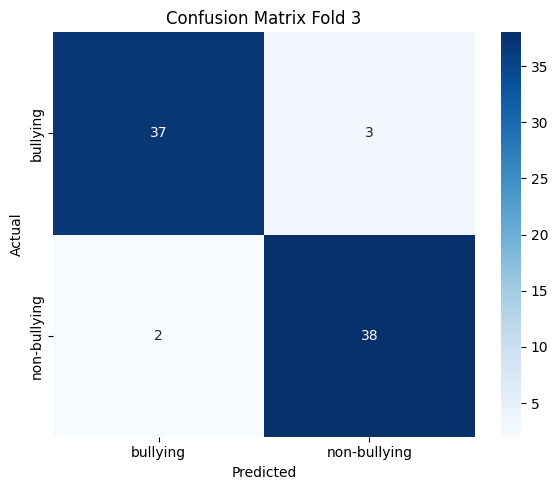


===== FOLD 4 =====
Learning Rate: 2e-05 | Fold 4/5
Epoch 1 | Loss: 0.8805 | Acc: 0.9125
Epoch 2 | Loss: 0.2662 | Acc: 0.9000
Epoch 3 | Loss: 0.1103 | Acc: 0.9125
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9125
Precision: 0.9255
Recall   : 0.9125
F1 Score : 0.9118

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.85      1.00      0.92        40
non-bullying       1.00      0.82      0.90        40

    accuracy                           0.91        80
   macro avg       0.93      0.91      0.91        80
weighted avg       0.93      0.91      0.91        80


Confusion Matrix:
[[40  0]
 [ 7 33]]


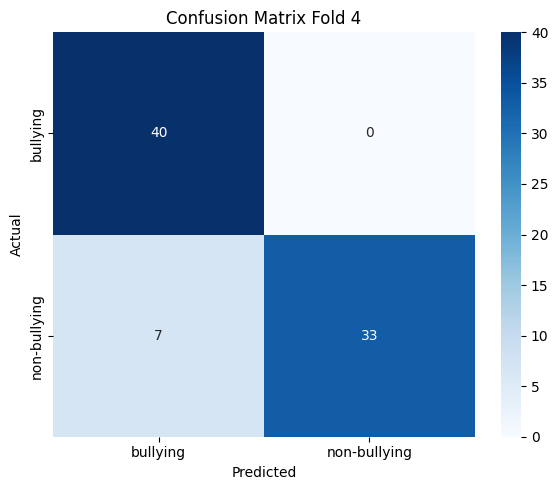


===== FOLD 5 =====
Learning Rate: 2e-05 | Fold 5/5
Epoch 1 | Loss: 0.6872 | Acc: 0.9125
Epoch 2 | Loss: 0.1918 | Acc: 0.9500
Epoch 3 | Loss: 0.0772 | Acc: 0.9750
Epoch 4 | Loss: 0.0448 | Acc: 0.9750
Epoch 5 | Loss: 0.0190 | Acc: 0.9750
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9750
Precision: 0.9762
Recall   : 0.9750
F1 Score : 0.9750

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.95      1.00      0.98        40
non-bullying       1.00      0.95      0.97        40

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80


Confusion Matrix:
[[40  0]
 [ 2 38]]


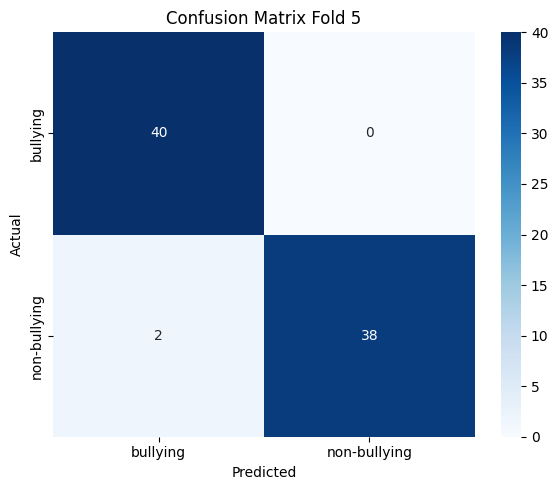


EKSPERIMEN LEARNING RATE = 3e-05


===== FOLD 1 =====
Learning Rate: 3e-05 | Fold 1/5
Epoch 1 | Loss: 0.7224 | Acc: 0.9125
Epoch 2 | Loss: 0.1684 | Acc: 0.9375
Epoch 3 | Loss: 0.0257 | Acc: 0.9625
Epoch 4 | Loss: 0.0025 | Acc: 0.9750
Epoch 5 | Loss: 0.0009 | Acc: 0.9625

=== METRICS ===
Accuracy : 0.9750
Precision: 0.9750
Recall   : 0.9750
F1 Score : 0.9750

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.97      0.97      0.97        40
non-bullying       0.97      0.97      0.97        40

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80


Confusion Matrix:
[[39  1]
 [ 1 39]]


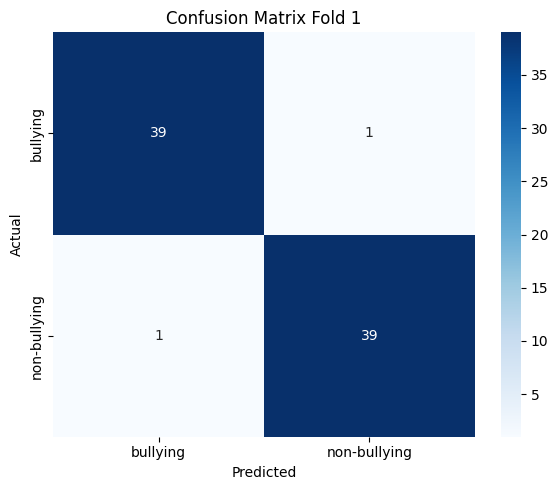


===== FOLD 2 =====
Learning Rate: 3e-05 | Fold 2/5
Epoch 1 | Loss: 0.8394 | Acc: 0.9000
Epoch 2 | Loss: 0.2268 | Acc: 0.7875
Epoch 3 | Loss: 0.1539 | Acc: 0.9000
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9000
Precision: 0.9000
Recall   : 0.9000
F1 Score : 0.9000

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.90      0.90      0.90        40
non-bullying       0.90      0.90      0.90        40

    accuracy                           0.90        80
   macro avg       0.90      0.90      0.90        80
weighted avg       0.90      0.90      0.90        80


Confusion Matrix:
[[36  4]
 [ 4 36]]


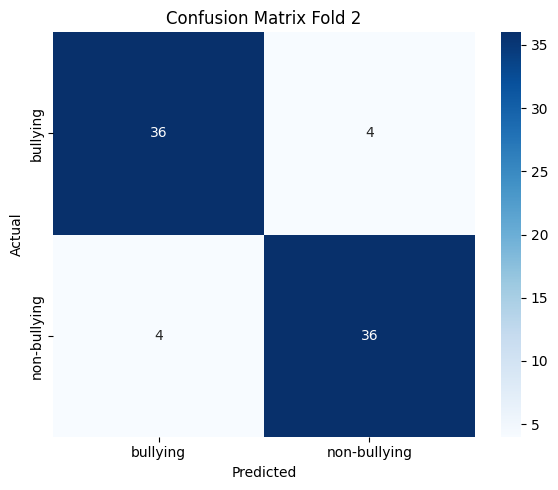


===== FOLD 3 =====
Learning Rate: 3e-05 | Fold 3/5
Epoch 1 | Loss: 0.6733 | Acc: 0.9375
Epoch 2 | Loss: 0.1368 | Acc: 0.9625
Epoch 3 | Loss: 0.0647 | Acc: 0.9375
Epoch 4 | Loss: 0.0132 | Acc: 0.9375
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9625
Precision: 0.9628
Recall   : 0.9625
F1 Score : 0.9625

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.95      0.97      0.96        40
non-bullying       0.97      0.95      0.96        40

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80


Confusion Matrix:
[[39  1]
 [ 2 38]]


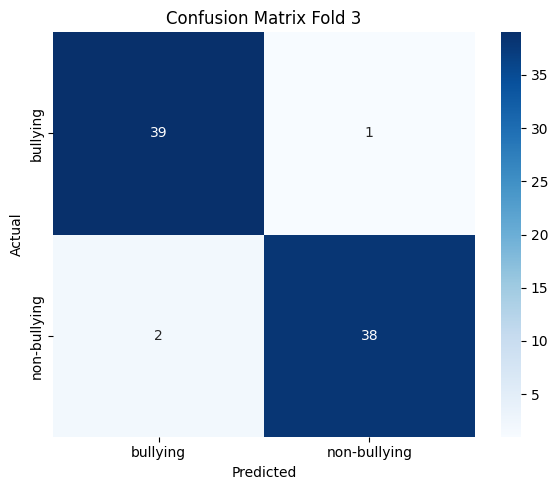


===== FOLD 4 =====
Learning Rate: 3e-05 | Fold 4/5
Epoch 1 | Loss: 0.7800 | Acc: 0.8875
Epoch 2 | Loss: 0.1662 | Acc: 0.9125
Epoch 3 | Loss: 0.0613 | Acc: 0.9125
Epoch 4 | Loss: 0.0071 | Acc: 0.9125
Early stopping triggered.

=== METRICS ===
Accuracy : 0.9125
Precision: 0.9190
Recall   : 0.9125
F1 Score : 0.9122

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.87      0.97      0.92        40
non-bullying       0.97      0.85      0.91        40

    accuracy                           0.91        80
   macro avg       0.92      0.91      0.91        80
weighted avg       0.92      0.91      0.91        80


Confusion Matrix:
[[39  1]
 [ 6 34]]


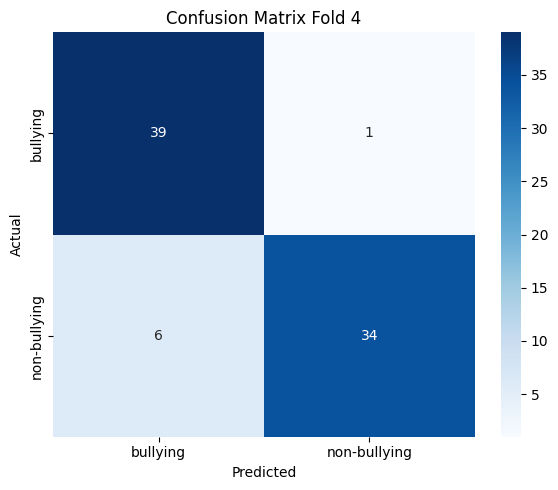


===== FOLD 5 =====
Learning Rate: 3e-05 | Fold 5/5
Epoch 1 | Loss: 0.7078 | Acc: 0.9125
Epoch 2 | Loss: 0.2040 | Acc: 0.9250
Epoch 3 | Loss: 0.1122 | Acc: 0.9500
Epoch 4 | Loss: 0.0338 | Acc: 0.9625
Epoch 5 | Loss: 0.0112 | Acc: 0.9625

=== METRICS ===
Accuracy : 0.9625
Precision: 0.9651
Recall   : 0.9625
F1 Score : 0.9624

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    bullying       0.93      1.00      0.96        40
non-bullying       1.00      0.93      0.96        40

    accuracy                           0.96        80
   macro avg       0.97      0.96      0.96        80
weighted avg       0.97      0.96      0.96        80


Confusion Matrix:
[[40  0]
 [ 3 37]]


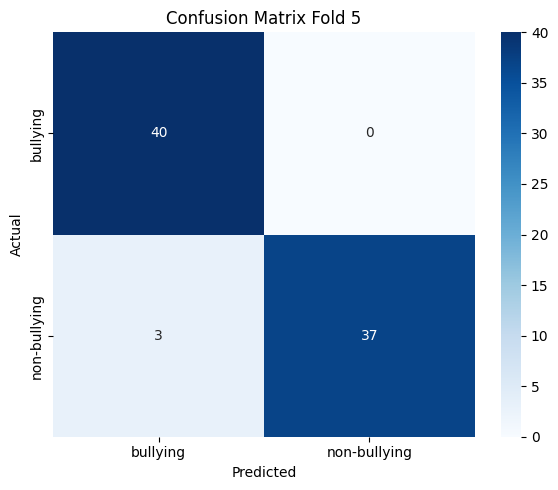

In [ ]:
def run_cross_validation(lr):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_dir = f"cv_results_lr_{lr}_{timestamp}"
    os.makedirs(output_dir, exist_ok=True)

    for fold, (train_idx, val_idx) in enumerate(kf.split(texts, labels)):
        print(f"\n===== FOLD {fold+1} =====")
        print(f"Learning Rate: {lr} | Fold {fold+1}/{CONFIG['n_splits']}")

        train_dataset = TextDataset(
            [texts[i] for i in train_idx],
            [labels[i] for i in train_idx]
        )

        val_dataset = TextDataset(
            [texts[i] for i in val_idx],
            [labels[i] for i in val_idx]
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=CONFIG["batch_size"],
            shuffle=True
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=CONFIG["batch_size"]
        )

        model, optimizer, criterion = setup_model(device, lr)

        total_steps = len(train_loader) * CONFIG["epochs"]

        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(CONFIG["warmup_ratio"] * total_steps),
            num_training_steps=total_steps
        )

        best_acc = 0
        best_model = None
        patience_counter = 0

        for epoch in range(CONFIG["epochs"]):

            loss = train_one_epoch(
                model,
                train_loader,
                optimizer,
                scheduler,
                criterion,
                device
            )

            preds, labels_true, texts_val, probs = evaluate(
                model,
                val_loader,
                device
            )

            acc = accuracy_score(labels_true, preds)

            print(
                f"Epoch {epoch+1} | Loss: {loss:.4f} | Acc: {acc:.4f}"
            )

            if acc > best_acc:
                best_acc = acc
                best_model = copy.deepcopy(model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= CONFIG["patience"]:
                print("Early stopping triggered.")
                break

        save_dir = os.path.join(output_dir, f"fold_{fold+1}_model")
        os.makedirs(save_dir, exist_ok=True)

        torch.save(model.state_dict(), os.path.join(save_dir, "model.pth"))
        tokenizer.save_pretrained(save_dir)

        preds, labels_true, texts_val, probs = evaluate(
            model,
            val_loader,
            device
        )

        acc = accuracy_score(labels_true, preds)
        precision = precision_score(
            labels_true,
            preds,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            labels_true,
            preds,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            labels_true,
            preds,
            average="weighted",
            zero_division=0
        )

        print("\n=== METRICS ===")
        print(f"Accuracy : {acc:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall   : {recall:.4f}")
        print(f"F1 Score : {f1:.4f}")
        print("\n=== CLASSIFICATION REPORT ===")
        print(
            classification_report(
                labels_true,
                preds,
                target_names=CLASS_NAMES,
                zero_division=0
            )
        )

        df_result = pd.DataFrame({
            "text": texts_val,
            "true": labels_true,
            "pred": preds
        })

        for i, name in enumerate(CLASS_NAMES):
            df_result[f"{name}_prob"] = [p[i] for p in probs]

        df_result["status"] = (
            df_result["true"] == df_result["pred"]
        )

        file_path = os.path.join(
            output_dir,
            f"fold_{fold+1}_result.csv"
        )

        df_result.to_csv(
            file_path,
            index=False
        )

        cm = confusion_matrix(labels_true, preds)

        print("\nConfusion Matrix:")
        print(cm)

        plt.figure(figsize=(6, 5))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES
        )

        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix Fold {fold+1}")

        plt.tight_layout()
        plt.show()

for lr in LEARNING_RATES:
    print("\n" + "=" * 80)
    print(f"EKSPERIMEN LEARNING RATE = {lr}")
    print("=" * 80 + "\n")
    run_cross_validation(lr)